# Day-Ahead PML Forecasting: Master Model Comparison & Final Out-of-Sample Test Evaluation

This notebook represents the capstone evaluation of the Day-Ahead Market (MDA) forecasting pipeline for hourly Local Marginal Prices (PML) across the 9 Monclova load-zone nodes.

1. **Validation Benchmark Ring (Q1 2025: 2,160 hourly intervals per node, totaling 19,440 node-hour observations):**
   - Head-to-head comparison across all 9 nodes: **Daily Persistence ($t-24$)**, **Weekly Persistence ($t-168$)**, **SARIMAX$(1,0,1)\times(1,1,0)_{24}$**, and **Global Multi-Node XGBoost**.
   - Standardized evaluation with **MAE** (primary), **RMSE** (volatility penalty), and **rMAE** (*Relative MAE* vs. Daily Persistence baseline).
   - Comparative 3-way visualizations across illustrative operating and stress-test weeks.
2. **Final Out-of-Sample Test Evaluation (Q2 2025: 2,184 hourly intervals per node, totaling 19,656 node-hour observations):**
   - Out-of-sample evaluation of the model selected in Q1 validation (**Global XGBoost**) on the Q2 test partition (April 1 – June 30, 2025). Test results are not used for further model selection or tuning.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.models.metrics import compute_mae, compute_rmse
from src.models.sarimax import (
    prepare_sarimax_features,
    fit_sarimax_model,
    rolling_day_ahead_forecast,
)
from src.models.xgboost import (
    FEATURE_COLS,
    build_xgboost_features,
    train_global_xgboost,
    predict_global_xgboost,
)

## Data Ingestion & Model Calibration on 2024
We load the validated interim dataset (`data/interim/pml_mda.parquet`). Both models use the January 8–December 31, 2024 training period (after 168h warmup). SARIMAX parameters are estimated on 8,616 observations from `06MON-115`, while global XGBoost is trained on 77,544 node-hour observations across all nine nodes.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "pml_mda.parquet"
raw_df = pd.read_parquet(DATA_PATH)
all_nodes = sorted(raw_df["clv_nodo"].unique())

print(f"Loaded dataset: {len(raw_df):,} total records across {len(all_nodes)} nodes.")

# Calibrate reference SARIMAX model on node 06MON-115
REF_NODE = "06MON-115"
y_ref, exog_ref = prepare_sarimax_features(raw_df, node=REF_NODE)
print(f"Fitting reference SARIMAX(1, 0, 1)x(1, 1, 0)_24 on {REF_NODE} (2024)...")
sarimax_res = fit_sarimax_model(
    train_y=y_ref["2024-01-08":"2024-12-31"],
    train_exog=exog_ref.loc["2024-01-08":"2024-12-31"],
    order=(1, 0, 1),
    seasonal_order=(1, 1, 0, 24),
)

# Train Global Multi-Node XGBoost on all 9 nodes
df_feat = build_xgboost_features(raw_df)
train_mask = (df_feat["timestamp"] >= "2024-01-08") & (df_feat["timestamp"] <= "2024-12-31 23:00:00")
train_df = df_feat[train_mask].copy().reset_index(drop=True)

print(f"Training Global XGBoost on {len(train_df):,} rows (L1 loss, 300 estimators, max_depth=6)...")
xgb_model = train_global_xgboost(
    train_df=train_df,
    feature_cols=FEATURE_COLS,
    target_col="pml",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
print("Calibration complete.")

Loaded dataset: 118,152 total records across 9 nodes.
Fitting reference SARIMAX(1, 0, 1)x(1, 1, 0)_24 on 06MON-115 (2024)...
Training Global XGBoost on 77,544 rows (L1 loss, 300 estimators, max_depth=6)...
Calibration complete.


## Validation Benchmark Ring (Q1 2025: 2,160 Hourly Intervals per Node, 19,440 Node-Hour Observations)
We evaluate all candidate models across all 9 nodes during Q1 2025. In addition to MAE and RMSE, we report **rMAE** (*Relative MAE* vs. Daily Persistence baseline, $\text{rMAE} = \text{MAE} / \text{MAE}_{\text{daily}}$), where $\text{rMAE} < 1$ indicates a lower MAE than daily persistence over the same evaluation period.

In [3]:
print("Executing Day-Ahead rolling forecasts across all 9 nodes (Q1 2025)...")

val_mask = (df_feat["timestamp"] >= "2025-01-01") & (df_feat["timestamp"] <= "2025-03-31 23:00:00")
val_df = df_feat[val_mask].copy().reset_index(drop=True)
val_df["pml_pred_xgb"] = predict_global_xgboost(xgb_model, val_df, feature_cols=FEATURE_COLS).values

val_records = []
sarimax_val_preds = {}

for node in all_nodes:
    #SARIMAX forecast via Kalman filter transfer
    y_n, exog_n = prepare_sarimax_features(raw_df, node=node)
    tr_y, tr_ex = y_n["2024-01-08":"2024-12-31"], exog_n.loc["2024-01-08":"2024-12-31"]
    vl_y, vl_ex = y_n["2025-01-01":"2025-03-31"], exog_n.loc["2025-01-01":"2025-03-31"]
    sar_pred_n = rolling_day_ahead_forecast(sarimax_res, tr_y, tr_ex, vl_y, vl_ex)
    sarimax_val_preds[node] = sar_pred_n

    # Extract validation slice for node
    node_val = val_df[val_df["clv_nodo"] == node].sort_values("timestamp").reset_index(drop=True)
    assert sar_pred_n.index.equals(pd.DatetimeIndex(node_val["timestamp"])), "SARIMAX predictions and actual values are not aligned"
    y_true = node_val["pml"].values
    y_daily = node_val["pml_lag_24"].values
    y_weekly = node_val["pml_lag_168"].values
    y_xgb = node_val["pml_pred_xgb"].values
    y_sar = sar_pred_n.values

    mae_daily = compute_mae(y_true, y_daily)
    mae_weekly = compute_mae(y_true, y_weekly)
    mae_sar = compute_mae(y_true, y_sar)
    mae_xgb = compute_mae(y_true, y_xgb)

    val_records.append({
        "Node": node,
        "Day_MAE": mae_daily,
        "Wk_MAE": mae_weekly,
        "SAR_MAE": mae_sar,
        "XGB_MAE": mae_xgb,
        "SAR_rMAE": mae_sar / mae_daily,
        "XGB_rMAE": mae_xgb / mae_daily,
        "Day_RMSE": compute_rmse(y_true, y_daily),
        "SAR_RMSE": compute_rmse(y_true, y_sar),
        "XGB_RMSE": compute_rmse(y_true, y_xgb),
    })

val_summary_df = pd.DataFrame(val_records)
for col in ['Day_MAE', 'Wk_MAE', 'SAR_MAE', 'XGB_MAE', 'Day_RMSE', 'SAR_RMSE', 'XGB_RMSE']:
    val_summary_df[col] = val_summary_df[col].round(2)
for col in ['SAR_rMAE', 'XGB_rMAE']:
    val_summary_df[col] = val_summary_df[col].round(3)

# Overall average row
avg_val_row = pd.DataFrame([{
    "Node": "OVERALL_AVERAGE",
    "Day_MAE": val_summary_df["Day_MAE"].mean().round(2),
    "Wk_MAE": val_summary_df["Wk_MAE"].mean().round(2),
    "SAR_MAE": val_summary_df["SAR_MAE"].mean().round(2),
    "XGB_MAE": val_summary_df["XGB_MAE"].mean().round(2),
    "SAR_rMAE": (val_summary_df["SAR_MAE"].mean() / val_summary_df["Day_MAE"].mean()).round(3),
    "XGB_rMAE": (val_summary_df["XGB_MAE"].mean() / val_summary_df["Day_MAE"].mean()).round(3),
    "Day_RMSE": val_summary_df["Day_RMSE"].mean().round(2),
    "SAR_RMSE": val_summary_df["SAR_RMSE"].mean().round(2),
    "XGB_RMSE": val_summary_df["XGB_RMSE"].mean().round(2),
}])

final_val_table = pd.concat([val_summary_df, avg_val_row], ignore_index=True)
print("=== Validation Benchmark Results Across All 9 Nodes (Q1 2025) ===")
print('--- Panel A: MAE and Relative MAE (rMAE vs. Daily Persistence) ---')
display(final_val_table[['Node', 'Day_MAE', 'Wk_MAE', 'SAR_MAE', 'XGB_MAE', 'SAR_rMAE', 'XGB_rMAE']])
print('--- Panel B: Root Mean Squared Error (RMSE) ---')
display(final_val_table[['Node', 'Day_RMSE', 'SAR_RMSE', 'XGB_RMSE']])


Executing Day-Ahead rolling forecasts across all 9 nodes (Q1 2025)...
=== Validation Benchmark Results Across All 9 Nodes (Q1 2025) ===
--- Panel A: MAE and Relative MAE (rMAE vs. Daily Persistence) ---


,Node,Day_MAE,Wk_MAE,SAR_MAE,XGB_MAE,SAR_rMAE,XGB_rMAE
0,06AEO-115,213.43,280.20,231.67,198.27,1.085,0.929
1,06AHM-400,212.26,278.82,231.08,196.74,1.089,0.927
2,06FRO-115,212.45,278.97,231.13,196.71,1.088,0.926
3,06GRA-115,213.31,280.03,231.56,198.10,1.086,0.929
4,06MON-115,212.73,279.52,231.37,197.41,1.088,0.928
5,06MON-230,212.77,279.49,231.38,197.45,1.087,0.928
6,06RGS-115,212.89,279.51,231.35,197.13,1.087,0.926
7,06TKS-115,212.48,279.01,231.15,196.91,1.088,0.927
8,06XOC-115,213.29,279.99,231.53,198.28,1.086,0.930
9,OVERALL_AVERAGE,212.85,279.50,231.36,197.44,1.087,0.928


--- Panel B: Root Mean Squared Error (RMSE) ---


,Node,Day_RMSE,SAR_RMSE,XGB_RMSE
0,06AEO-115,315.78,313.60,290.65
1,06AHM-400,314.20,312.66,288.55
2,06FRO-115,314.42,312.76,288.56
3,06GRA-115,315.58,313.46,290.53
4,06MON-115,314.86,313.10,289.69
5,06MON-230,314.86,313.10,289.76
6,06RGS-115,315.03,313.12,288.66
7,06TKS-115,314.47,312.79,288.75
8,06XOC-115,315.52,313.45,290.60
9,OVERALL_AVERAGE,314.97,313.12,289.53


## Multi-Regime Visualizations
Two illustrative validation weeks are shown to examine different observed price patterns for reference node `06MON-115`. Model selection is based on full-quarter metrics.
1. **Illustrative Stress Week (Jan 13–19, 2025):** Sunday price movement testing weekend adjustment dynamics.
2. **Illustrative Stable Week (Feb 3–9, 2025):** Moderate winter operating conditions (Mean PML: 580.06 MXN/MWh).


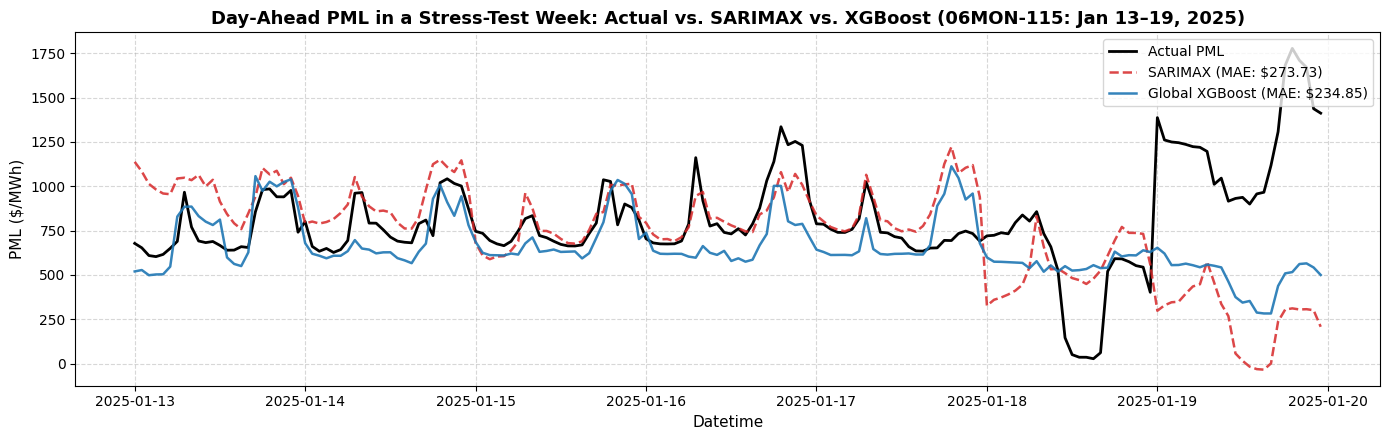

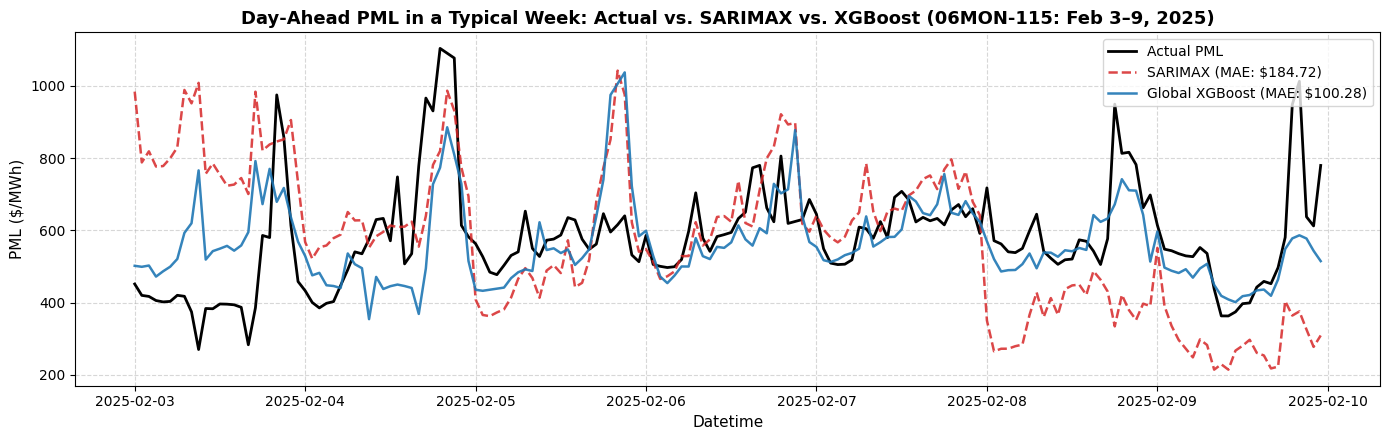

In [4]:
ref_val_df = val_df[val_df["clv_nodo"] == REF_NODE].set_index("timestamp").sort_index()

# 1. Stress-Test Operating Week: Jan 13 - Jan 19, 2025
stress_mask = (ref_val_df.index >= "2025-01-13") & (ref_val_df.index <= "2025-01-19 23:00:00")
stress_act = ref_val_df.loc[stress_mask, "pml"]
stress_xgb = ref_val_df.loc[stress_mask, "pml_pred_xgb"]
stress_sar = sarimax_val_preds[REF_NODE].loc[stress_mask]

mae_str_sar = compute_mae(stress_act.values, stress_sar.values)
mae_str_xgb = compute_mae(stress_act.values, stress_xgb.values)

plt.figure(figsize=(14, 4.5))
plt.plot(stress_act.index, stress_act.values, label="Actual PML", color="black", linewidth=2.0)
plt.plot(stress_sar.index, stress_sar.values, label=f"SARIMAX (MAE: ${mae_str_sar:.2f})", color="#d62728", linestyle="--", linewidth=1.8, alpha=0.85)
plt.plot(stress_xgb.index, stress_xgb.values, label=f"Global XGBoost (MAE: ${mae_str_xgb:.2f})", color="#1f77b4", linestyle="-", linewidth=1.8, alpha=0.9)

plt.title(f"Day-Ahead PML in a Stress-Test Week: Actual vs. SARIMAX vs. XGBoost ({REF_NODE}: Jan 13–19, 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Typical Operating Week: Feb 3 - Feb 9, 2025
norm_mask = (ref_val_df.index >= "2025-02-03") & (ref_val_df.index <= "2025-02-09 23:00:00")
norm_act = ref_val_df.loc[norm_mask, "pml"]
norm_xgb = ref_val_df.loc[norm_mask, "pml_pred_xgb"]
norm_sar = sarimax_val_preds[REF_NODE].loc[norm_mask]

mae_norm_sar = compute_mae(norm_act.values, norm_sar.values)
mae_norm_xgb = compute_mae(norm_act.values, norm_xgb.values)

plt.figure(figsize=(14, 4.5))
plt.plot(norm_act.index, norm_act.values, label="Actual PML", color="black", linewidth=2.0)
plt.plot(norm_sar.index, norm_sar.values, label=f"SARIMAX (MAE: ${mae_norm_sar:.2f})", color="#d62728", linestyle="--", linewidth=1.8, alpha=0.85)
plt.plot(norm_xgb.index, norm_xgb.values, label=f"Global XGBoost (MAE: ${mae_norm_xgb:.2f})", color="#1f77b4", linestyle="-", linewidth=1.8, alpha=0.9)

plt.title(f"Day-Ahead PML in a Typical Week: Actual vs. SARIMAX vs. XGBoost ({REF_NODE}: Feb 3–9, 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Final Out-of-Sample Test Evaluation (Q2 2025)
We use the out-of-sample Test partition (**April 1 to June 30, 2025: 2,184 hourly intervals per node, totaling 19,656 node-hour observations**) and evaluate the selected model (**Global XGBoost**) against the operational Daily Persistence baseline. Test results are not used for further model selection or tuning.

In [5]:
test_mask = (df_feat["timestamp"] >= "2025-04-01") & (df_feat["timestamp"] <= "2025-06-30 23:00:00")
test_df = df_feat[test_mask].copy().reset_index(drop=True)

print(f"Test Partition (Q2 2025): {len(test_df):,} records | Nulls in features: {test_df[FEATURE_COLS].isna().sum().sum()}")

# Predict Test partition with Global XGBoost
test_df["pml_pred_xgb"] = predict_global_xgboost(xgb_model, test_df, feature_cols=FEATURE_COLS).values

test_records = []
for node in all_nodes:
    node_test = test_df[test_df["clv_nodo"] == node].sort_values("timestamp").reset_index(drop=True)
    y_test_true = node_test["pml"].values
    y_test_pers = node_test["pml_lag_24"].values
    y_test_xgb = node_test["pml_pred_xgb"].values

    mae_pers = compute_mae(y_test_true, y_test_pers)
    mae_xgb = compute_mae(y_test_true, y_test_xgb)
    rmse_pers = compute_rmse(y_test_true, y_test_pers)
    rmse_xgb = compute_rmse(y_test_true, y_test_xgb)

    test_records.append({
        "Node": node,
        "Day_MAE": mae_pers,
        "XGB_MAE": mae_xgb,
        "XGB_rMAE": mae_xgb / mae_pers,
        "Day_RMSE": rmse_pers,
        "XGB_RMSE": rmse_xgb,
    })

test_summary_df = pd.DataFrame(test_records)
for col in ['Day_MAE', 'XGB_MAE', 'Day_RMSE', 'XGB_RMSE']:
    test_summary_df[col] = test_summary_df[col].round(2)
test_summary_df['XGB_rMAE'] = test_summary_df['XGB_rMAE'].round(3)

# Overall average row
avg_test_row = pd.DataFrame([{
    "Node": "OVERALL_AVERAGE",
    "Day_MAE": test_summary_df["Day_MAE"].mean().round(2),
    "XGB_MAE": test_summary_df["XGB_MAE"].mean().round(2),
    "XGB_rMAE": (test_summary_df["XGB_MAE"].mean() / test_summary_df["Day_MAE"].mean()).round(3),
    "Day_RMSE": test_summary_df["Day_RMSE"].mean().round(2),
    "XGB_RMSE": test_summary_df["XGB_RMSE"].mean().round(2),
}])

final_test_table = pd.concat([test_summary_df, avg_test_row], ignore_index=True)
print("=== Final Out-of-Sample Test Set Performance Across All 9 Nodes (Q2 2025) ===")
display(final_test_table)

Test Partition (Q2 2025): 19,656 records | Nulls in features: 0
=== Final Out-of-Sample Test Set Performance Across All 9 Nodes (Q2 2025) ===


,Node,Day_MAE,XGB_MAE,XGB_rMAE,Day_RMSE,XGB_RMSE
0,06AEO-115,168.82,141.19,0.836,285.62,243.46
1,06AHM-400,167.64,138.70,0.827,283.99,240.64
2,06FRO-115,167.70,138.97,0.829,284.04,240.68
3,06GRA-115,168.83,141.19,0.836,285.70,243.45
4,06MON-115,167.95,139.69,0.832,284.31,241.20
5,06MON-230,168.02,139.70,0.831,284.45,241.26
6,06RGS-115,168.31,140.03,0.832,284.93,242.02
7,06TKS-115,167.75,139.18,0.830,284.11,240.95
8,06XOC-115,168.69,140.91,0.835,285.46,242.99
9,OVERALL_AVERAGE,168.19,139.95,0.832,284.73,241.85


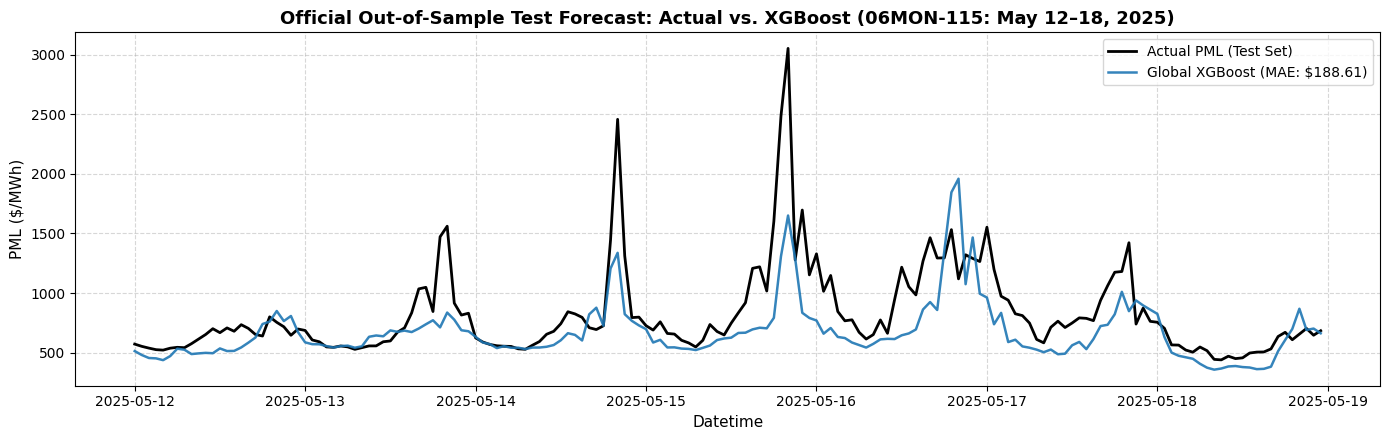

Test Week Performance (May 12–18, 2025): MAE = $188.61 MXN/MWh


In [6]:
# Representative Test Week Visualization on Reference Node (May 12 - May 18, 2025)
ref_test = test_df[test_df["clv_nodo"] == REF_NODE].set_index("timestamp").sort_index()
test_plot_mask = (ref_test.index >= "2025-05-12") & (ref_test.index <= "2025-05-18 23:00:00")

plot_t_act = ref_test.loc[test_plot_mask, "pml"]
plot_t_xgb = ref_test.loc[test_plot_mask, "pml_pred_xgb"]
mae_test_week = compute_mae(plot_t_act.values, plot_t_xgb.values)

plt.figure(figsize=(14, 4.5))
plt.plot(plot_t_act.index, plot_t_act.values, label="Actual PML (Test Set)", color="black", linewidth=2.0)
plt.plot(plot_t_xgb.index, plot_t_xgb.values, label=f"Global XGBoost (MAE: ${mae_test_week:.2f})", color="#1f77b4", linestyle="-", linewidth=1.8, alpha=0.9)

plt.title(f"Official Out-of-Sample Test Forecast: Actual vs. XGBoost ({REF_NODE}: May 12–18, 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Test Week Performance (May 12–18, 2025): MAE = ${mae_test_week:.2f} MXN/MWh")

## Executive Findings

### Performance Progression across Pipeline Horizons
- **Validation Set (Q1 2025: 2,160 hourly intervals per node, totaling 19,440 node-hour observations):**
  - Daily Persistence: MAE = 212.85 MXN/MWh | RMSE = 314.97 MXN/MWh | rMAE = 1.000
  - SARIMAX(1,0,1)x(1,1,0)_24: MAE = 231.36 MXN/MWh | RMSE = 313.12 MXN/MWh | rMAE = 1.087 (+8.7% error vs. baseline)
  - **Global Multi-Node XGBoost:** MAE = 197.44 MXN/MWh | RMSE = 289.53 MXN/MWh | **rMAE = 0.928 (-7.2% error reduction)**
- **Final Test Set (Q2 2025: 2,184 hourly intervals per node, totaling 19,656 node-hour observations):**
  - Daily Persistence: MAE = 168.19 MXN/MWh | RMSE = 284.73 MXN/MWh | rMAE = 1.000
  - **Global Multi-Node XGBoost:** MAE = 139.95 MXN/MWh | RMSE = 241.85 MXN/MWh | **rMAE = 0.832 (-16.8% error reduction)**

### Key Modeling Takeaways
1. **Model Selection:**
   - XGBoost achieves the lowest MAE among the evaluated candidates across all nine nodes in Q1 validation. In Q2 test, it also outperforms daily persistence in both MAE and RMSE across all nine nodes.
2. **Out-of-Sample Performance:**
   - XGBoost reduces MAE relative to daily persistence by 7.2% in validation and 16.8% in test. These results support its predictive usefulness over the evaluated periods, but do not establish the absence of overfitting.
3. **Consistency Across Nodes:**
   - Test rMAE ranges from 0.827 to 0.836, indicating similar relative improvements over daily persistence across the nine nodes. This supports the feasibility of the shared model; independent nodal XGBoost models were not evaluated.

## 9-Node Spatial Grid Visualizations

I provide multi-panel $3 \times 3$ spatial grids displaying all 9 transmission nodes of the Monclova load zone simultaneously:
1. **Validation Multi-Model Ring (Feb 3–9, 2025):** Head-to-head comparison of Actual PML, SARIMAX, and Global XGBoost across all 9 nodes.
2. **Final Out-of-Sample Test Evaluation (May 12–18, 2025):** Actual PML vs. Global XGBoost across all 9 nodes.

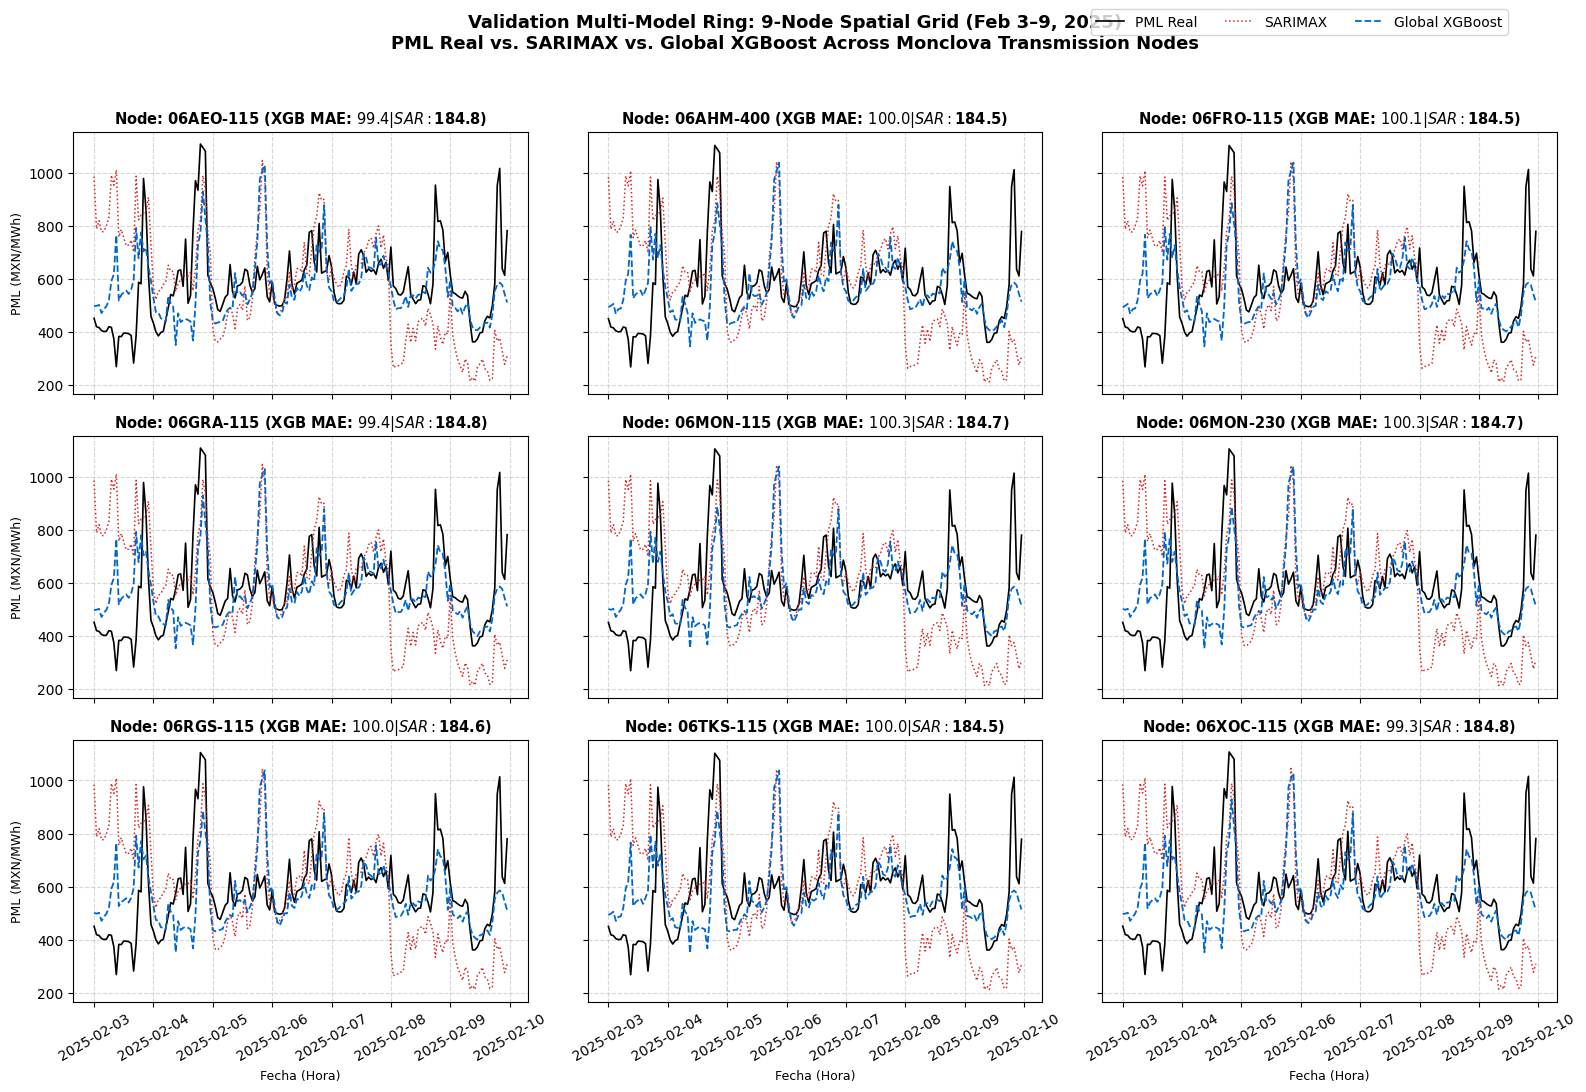

In [7]:
# 3x3 Spatial Grid for Validation Week (Feb 3 - Feb 9, 2025)
# Displays Actual PML vs. SARIMAX vs. Global XGBoost across all 9 nodes
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
axes = axes.flatten()

val_week_start, val_week_end = "2025-02-03", "2025-02-09 23:00:00"

for idx, node in enumerate(all_nodes):
    ax = axes[idx]
    node_slice = val_df[(val_df["clv_nodo"] == node) & 
                        (val_df["timestamp"] >= val_week_start) & 
                        (val_df["timestamp"] <= val_week_end)].sort_values("timestamp").set_index("timestamp")
    
    sar_slice = sarimax_val_preds[node].loc[val_week_start:val_week_end]
    
    ax.plot(node_slice.index, node_slice["pml"], color="black", 
            label="PML Real" if idx == 0 else "", linewidth=1.2)
    ax.plot(sar_slice.index, sar_slice.values, color="#D62728", linestyle=":", 
            label="SARIMAX" if idx == 0 else "", linewidth=1.1)
    ax.plot(node_slice.index, node_slice["pml_pred_xgb"], color="#0066CC", linestyle="--", 
            label="Global XGBoost" if idx == 0 else "", linewidth=1.3)
    
    mae_x = compute_mae(node_slice["pml"].values, node_slice["pml_pred_xgb"].values)
    mae_s = compute_mae(node_slice["pml"].values, sar_slice.values)
    
    ax.set_title(f"Node: {node} (XGB MAE: ${mae_x:.1f} | SAR: ${mae_s:.1f})", fontsize=10.5, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)
    if idx % 3 == 0:
        ax.set_ylabel("PML (MXN/MWh)", fontsize=9)
    if idx >= 6:
        ax.set_xlabel("Fecha (Hora)", fontsize=9)
        ax.tick_params(axis="x", rotation=30)

fig.suptitle("Validation Multi-Model Ring: 9-Node Spatial Grid (Feb 3–9, 2025)\nPML Real vs. SARIMAX vs. Global XGBoost Across Monclova Transmission Nodes",
             fontsize=13, fontweight="bold", y=0.985)
fig.legend(loc="upper right", bbox_to_anchor=(0.95, 0.995), ncol=3, frameon=True)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


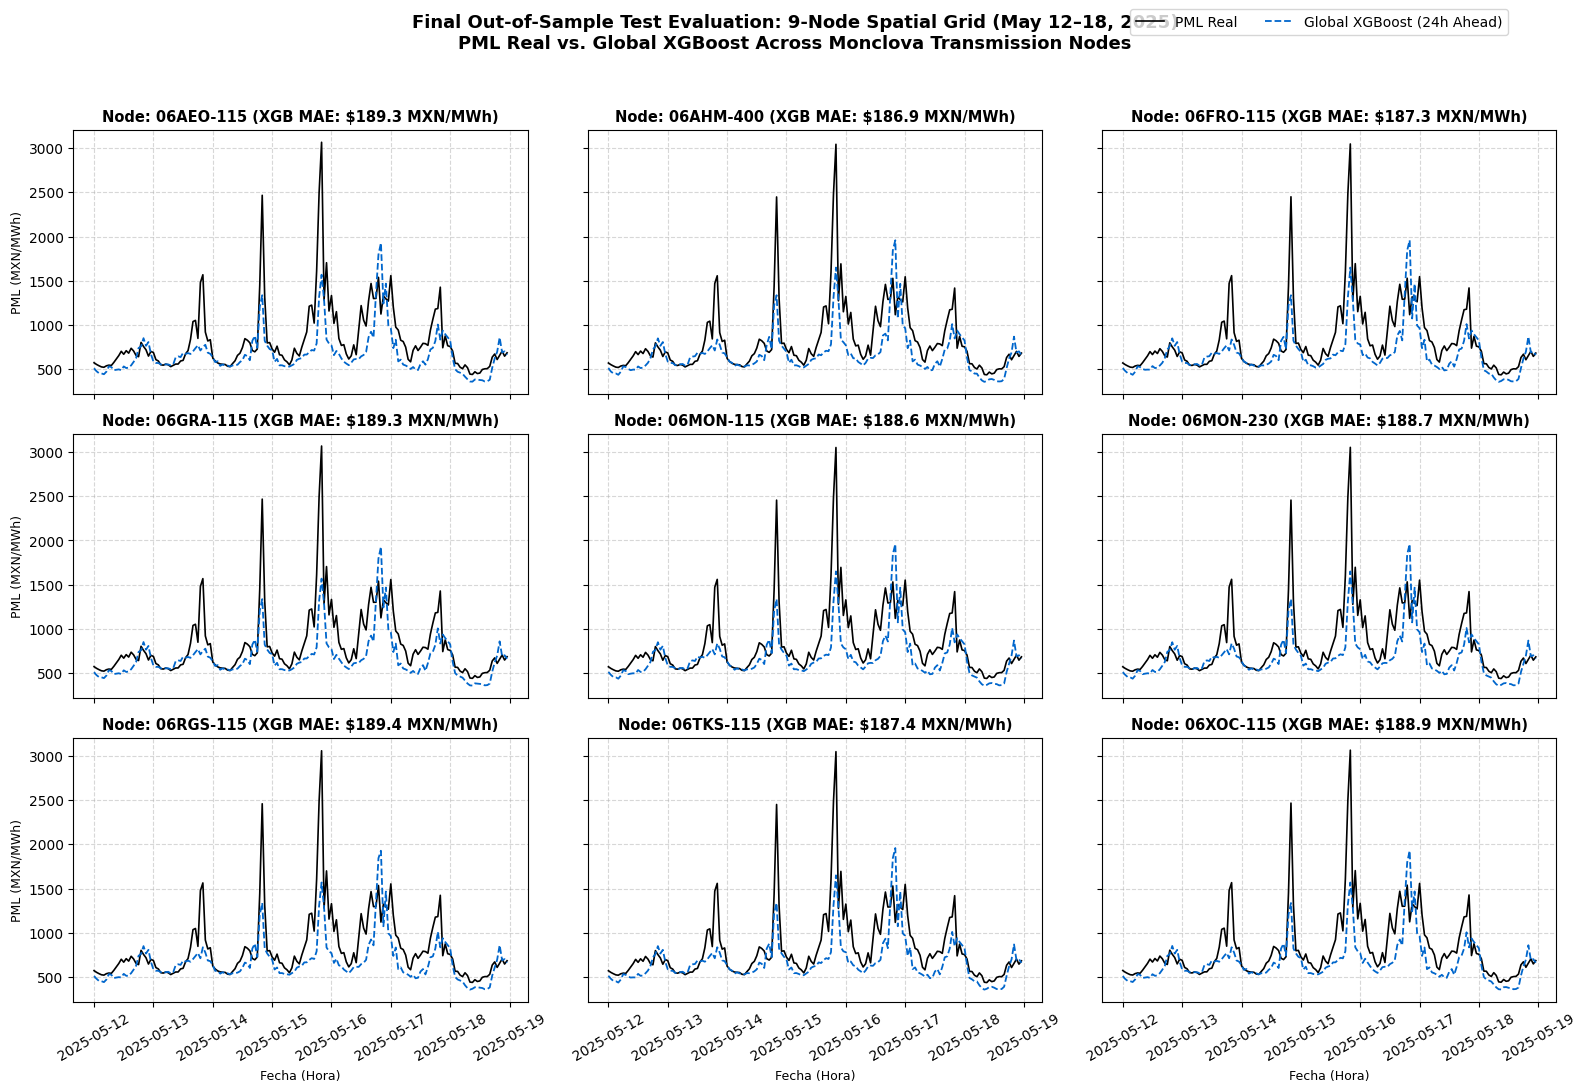

In [8]:
# Figure 2: 3x3 Spatial Grid for Final Test Week (May 12 - May 18, 2025)
# Displays Actual PML vs. Global XGBoost across all 9 nodes
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True, sharey=True)
axes = axes.flatten()

test_week_start, test_week_end = "2025-05-12", "2025-05-18 23:00:00"

for idx, node in enumerate(all_nodes):
    ax = axes[idx]
    node_slice = test_df[(test_df["clv_nodo"] == node) & 
                         (test_df["timestamp"] >= test_week_start) & 
                         (test_df["timestamp"] <= test_week_end)].sort_values("timestamp").set_index("timestamp")
    
    ax.plot(node_slice.index, node_slice["pml"], color="black", 
            label="PML Real" if idx == 0 else "", linewidth=1.2)
    ax.plot(node_slice.index, node_slice["pml_pred_xgb"], color="#0066CC", linestyle="--", 
            label="Global XGBoost (24h Ahead)" if idx == 0 else "", linewidth=1.3)
    
    mae_x = compute_mae(node_slice["pml"].values, node_slice["pml_pred_xgb"].values)
    ax.set_title(f"Node: {node} (XGB MAE: ${mae_x:.1f} MXN/MWh)", fontsize=10.5, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)
    if idx % 3 == 0:
        ax.set_ylabel("PML (MXN/MWh)", fontsize=9)
    if idx >= 6:
        ax.set_xlabel("Fecha (Hora)", fontsize=9)
        ax.tick_params(axis="x", rotation=30)

fig.suptitle("Final Out-of-Sample Test Evaluation: 9-Node Spatial Grid (May 12–18, 2025)\nPML Real vs. Global XGBoost Across Monclova Transmission Nodes",
             fontsize=13, fontweight="bold", y=0.985)
fig.legend(loc="upper right", bbox_to_anchor=(0.95, 0.995), ncol=2, frameon=True)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
